SPRINT 1 : DATA UNDERSTANDING & PREPROCESSING

Step 1: Data Collection & Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('mental_tiredness_score.csv')

In [3]:
# Check dataset size
print('Dataset Shape:', df.shape)

Dataset Shape: (15000, 18)


In [4]:
# check column names
print(df.columns)

Index(['number_of_decisions_made', 'context_switch_count',
       'notifications_received', 'screen_time_min', 'deep_work_min',
       'task_complexity_avg', 'caffeine_mg', 'break_frequency', 'sleep_hours',
       'deep_sleep_pct', 'hydration_l', 'mood', 'work_type',
       'work_environment', 'noise_level_db', 'temperature_c', 'workload_score',
       'mental_tiredness_score'],
      dtype='str')


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   number_of_decisions_made  15000 non-null  int64  
 1   context_switch_count      15000 non-null  int64  
 2   notifications_received    15000 non-null  int64  
 3   screen_time_min           15000 non-null  float64
 4   deep_work_min             15000 non-null  float64
 5   task_complexity_avg       15000 non-null  float64
 6   caffeine_mg               15000 non-null  float64
 7   break_frequency           15000 non-null  int64  
 8   sleep_hours               15000 non-null  float64
 9   deep_sleep_pct            15000 non-null  float64
 10  hydration_l               15000 non-null  float64
 11  mood                      15000 non-null  str    
 12  work_type                 15000 non-null  str    
 13  work_environment          15000 non-null  str    
 14  noise_level_db   

In [6]:
df.head()

,number_of_decisions_made,context_switch_count,notifications_received,screen_time_min,deep_work_min,task_complexity_avg,caffeine_mg,break_frequency,sleep_hours,deep_sleep_pct,hydration_l,mood,work_type,work_environment,noise_level_db,temperature_c,workload_score,mental_tiredness_score
0,110,14,70,196.5,65.1,7.0,136.1,1,7.84,26.75,2.05,Happy,Remote,Moderate Noise,53.8,19.8,3.3,22.17
1,122,9,66,256.4,135.2,6.5,83.9,3,7.18,17.82,1.82,Low,Remote,Noisy,38.9,18.7,4.6,25.35
2,113,4,55,387.3,54.2,10.0,176.5,5,5.52,27.78,1.92,Happy,Office,Quiet,42.0,26.4,7.9,34.36
3,113,8,45,300.3,107.1,4.8,164.7,2,8.47,3.48,1.89,Happy,Manual,Quiet,47.2,23.8,5.4,11.92
4,95,8,68,240.5,3.2,8.0,186.3,4,7.48,21.17,2.41,Happy,Manual,Moderate Noise,61.0,24.2,8.5,37.45


In [7]:
# y = target column
y = df['mental_tiredness_score']
y.head()


0    22.17
1    25.35
2    34.36
3    11.92
4    37.45
Name: mental_tiredness_score, dtype: float64

In [8]:
# X = all remaining columns
X = df.drop('mental_tiredness_score', axis=1)

## 1. Numerical columns vs target ( Scatter plots)

In [9]:
y = 'mental_tiredness_score'

In [10]:
y = df['mental_tiredness_score']

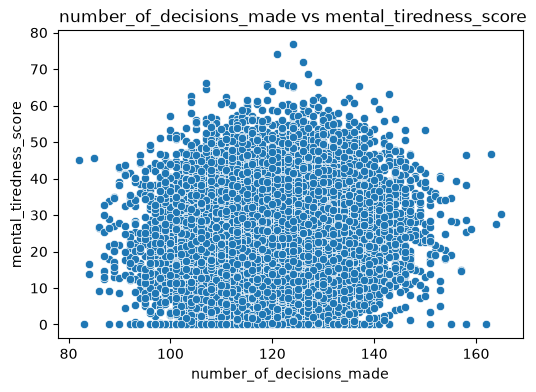

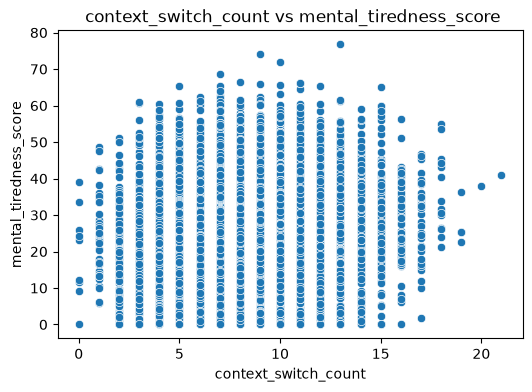

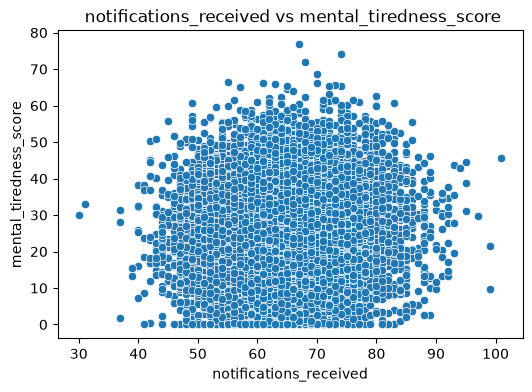

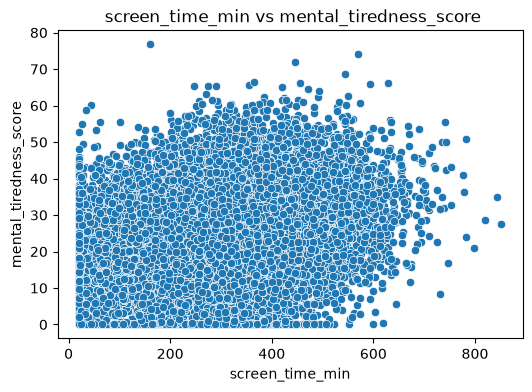

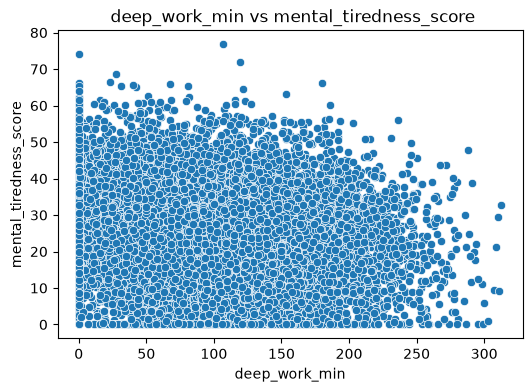

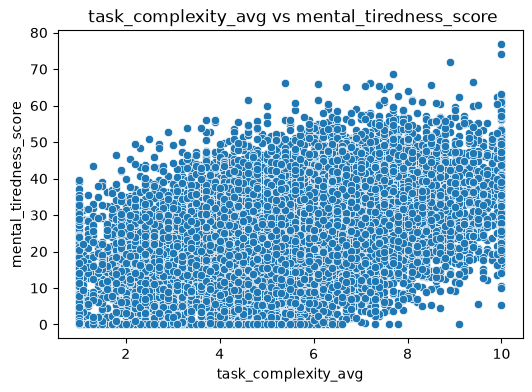

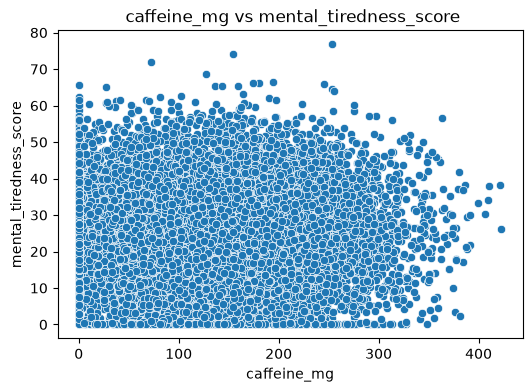

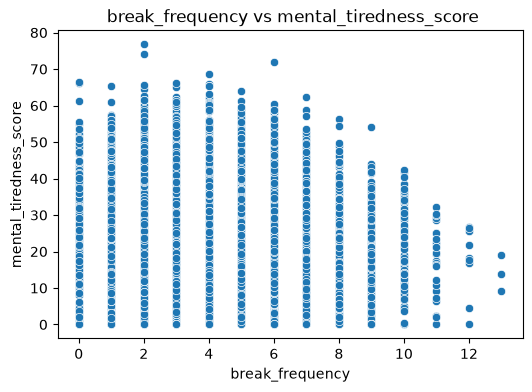

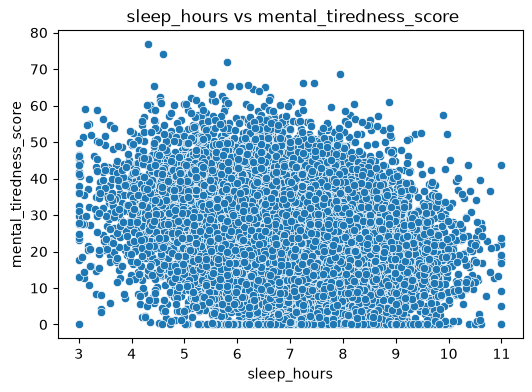

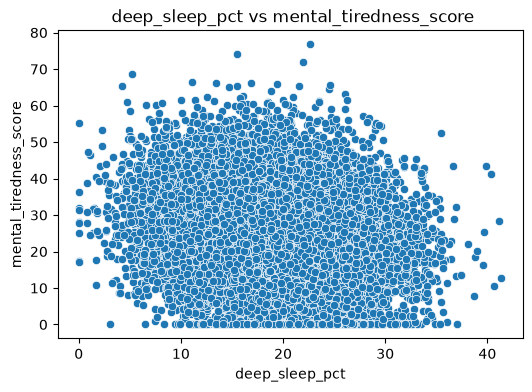

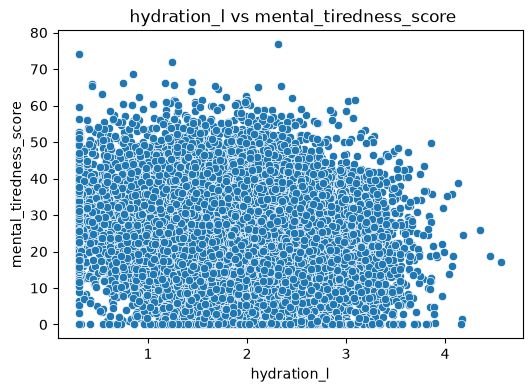

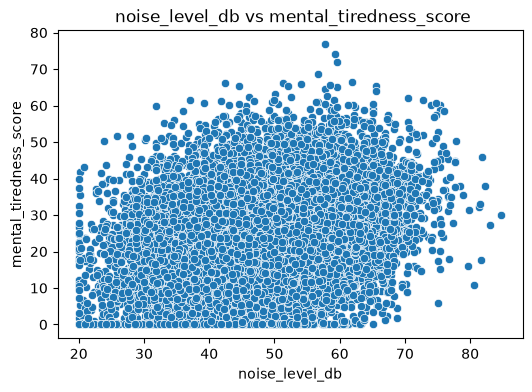

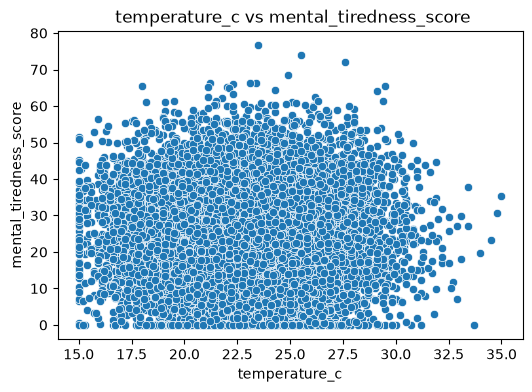

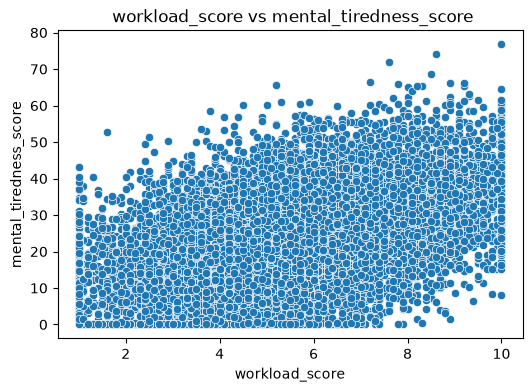

In [11]:
# numeric columns from X
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

# scatter plots

for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.scatterplot(x = X[col], y=y)
    plt.title(f' {col} vs mental_tiredness_score')
    plt.xlabel(col)
    plt.ylabel('mental_tiredness_score')
    plt.show()
    

## 2. Categorical columns vs target

C:\Users\User\AppData\Local\Temp\ipykernel_6888\3002730414.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include='object').columns


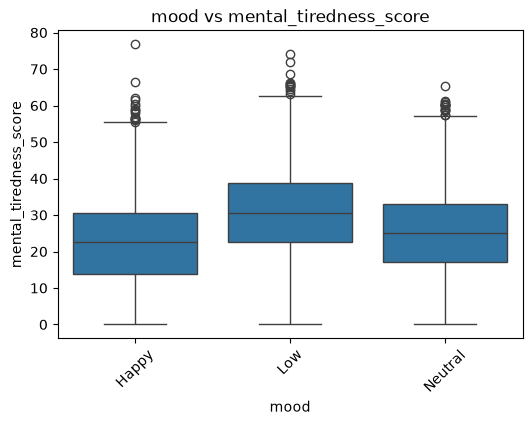

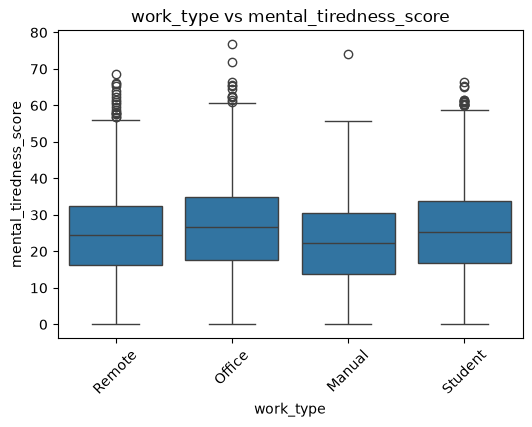

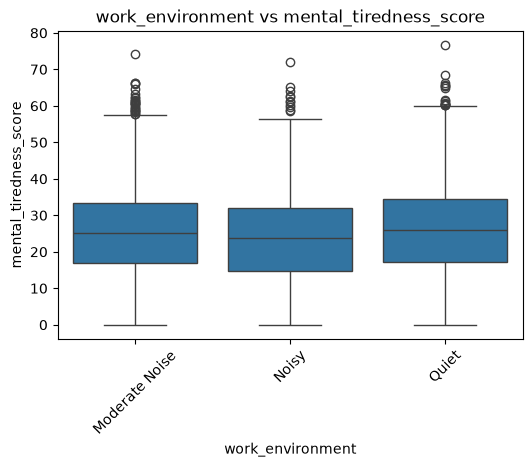

In [12]:
# categorical columns from X
cat_cols = X.select_dtypes(include='object').columns

for col in cat_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=X[col], y=y)
    plt.title(f'{col} vs mental_tiredness_score')
    plt.xticks(rotation=45)
    plt.show()

## Step 2 : Initial Data Inspection

In [13]:
df.head()

,number_of_decisions_made,context_switch_count,notifications_received,screen_time_min,deep_work_min,task_complexity_avg,caffeine_mg,break_frequency,sleep_hours,deep_sleep_pct,hydration_l,mood,work_type,work_environment,noise_level_db,temperature_c,workload_score,mental_tiredness_score
0,110,14,70,196.5,65.1,7.0,136.1,1,7.84,26.75,2.05,Happy,Remote,Moderate Noise,53.8,19.8,3.3,22.17
1,122,9,66,256.4,135.2,6.5,83.9,3,7.18,17.82,1.82,Low,Remote,Noisy,38.9,18.7,4.6,25.35
2,113,4,55,387.3,54.2,10.0,176.5,5,5.52,27.78,1.92,Happy,Office,Quiet,42.0,26.4,7.9,34.36
3,113,8,45,300.3,107.1,4.8,164.7,2,8.47,3.48,1.89,Happy,Manual,Quiet,47.2,23.8,5.4,11.92
4,95,8,68,240.5,3.2,8.0,186.3,4,7.48,21.17,2.41,Happy,Manual,Moderate Noise,61.0,24.2,8.5,37.45


In [14]:
df.tail()

,number_of_decisions_made,context_switch_count,notifications_received,screen_time_min,deep_work_min,task_complexity_avg,caffeine_mg,break_frequency,sleep_hours,deep_sleep_pct,hydration_l,mood,work_type,work_environment,noise_level_db,temperature_c,workload_score,mental_tiredness_score
14995,132,14,69,207.9,162.3,6.8,51.8,4,4.58,5.83,1.29,Low,Remote,Noisy,46.0,21.6,6.6,48.53
14996,111,11,49,365.2,69.4,7.7,67.0,1,7.39,18.18,1.65,Low,Student,Moderate Noise,42.0,26.0,6.6,50.75
14997,108,7,66,405.5,54.0,3.8,0.0,7,7.22,15.83,2.11,Low,Remote,Quiet,39.5,23.4,3.5,9.61
14998,143,8,64,402.8,18.2,3.0,0.0,5,7.89,16.72,0.38,Low,Office,Moderate Noise,54.4,27.1,6.0,32.05
14999,119,12,75,262.5,104.9,6.0,246.8,2,8.26,26.08,3.15,Neutral,Student,Quiet,27.5,22.2,2.8,8.97


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   number_of_decisions_made  15000 non-null  int64  
 1   context_switch_count      15000 non-null  int64  
 2   notifications_received    15000 non-null  int64  
 3   screen_time_min           15000 non-null  float64
 4   deep_work_min             15000 non-null  float64
 5   task_complexity_avg       15000 non-null  float64
 6   caffeine_mg               15000 non-null  float64
 7   break_frequency           15000 non-null  int64  
 8   sleep_hours               15000 non-null  float64
 9   deep_sleep_pct            15000 non-null  float64
 10  hydration_l               15000 non-null  float64
 11  mood                      15000 non-null  str    
 12  work_type                 15000 non-null  str    
 13  work_environment          15000 non-null  str    
 14  noise_level_db   

In [16]:
df.describe(include='all')

,number_of_decisions_made,context_switch_count,notifications_received,screen_time_min,deep_work_min,task_complexity_avg,caffeine_mg,break_frequency,sleep_hours,deep_sleep_pct,hydration_l,mood,work_type,work_environment,noise_level_db,temperature_c,workload_score,mental_tiredness_score
count,15000.000000,15000.000000,15000.00000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000,15000,15000,15000.000000,15000.000000,15000.000000,15000.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,4,3,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Happy,Student,Quiet,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6287,5238,6042,NaN,NaN,NaN,NaN
mean,120.079133,7.982133,64.96780,302.211107,96.698407,5.505333,131.170247,4.001733,6.893889,19.017639,1.892743,NaN,NaN,NaN,47.925353,23.000160,5.697280,25.189109
std,10.882327,2.837784,8.11442,136.575167,61.249273,1.957174,79.542710,2.017358,1.296186,5.958026,0.686356,NaN,NaN,NaN,9.880337,2.967518,1.941123,12.190013
min,82.000000,0.000000,30.00000,20.000000,0.000000,1.000000,0.000000,0.000000,3.000000,0.000000,0.300000,NaN,NaN,NaN,20.000000,15.000000,1.000000,0.000000
25%,113.000000,6.000000,59.00000,205.300000,50.100000,4.175000,72.200000,3.000000,6.010000,15.040000,1.430000,NaN,NaN,NaN,41.300000,21.000000,4.400000,16.690000
50%,120.000000,8.000000,65.00000,302.000000,94.800000,5.500000,129.000000,4.000000,6.900000,18.980000,1.890000,NaN,NaN,NaN,47.900000,23.000000,5.700000,25.220000
75%,127.000000,10.000000,70.00000,396.100000,138.800000,6.800000,185.500000,5.000000,7.780000,23.062500,2.350000,NaN,NaN,NaN,54.600000,25.000000,7.000000,33.460000


In [17]:
df.isnull().sum()

number_of_decisions_made    0
context_switch_count        0
notifications_received      0
screen_time_min             0
deep_work_min               0
task_complexity_avg         0
caffeine_mg                 0
break_frequency             0
sleep_hours                 0
deep_sleep_pct              0
hydration_l                 0
mood                        0
work_type                   0
work_environment            0
noise_level_db              0
temperature_c               0
workload_score              0
mental_tiredness_score      0
dtype: int64

# Unique Values

In [18]:
df.nunique()

number_of_decisions_made      82
context_switch_count          22
notifications_received        63
screen_time_min             5049
deep_work_min               2443
task_complexity_avg           91
caffeine_mg                 3096
break_frequency               14
sleep_hours                  743
deep_sleep_pct              2783
hydration_l                  373
mood                           3
work_type                      4
work_environment               3
noise_level_db               571
temperature_c                183
workload_score                91
mental_tiredness_score      4635
dtype: int64

## Step 3 : Data Cleaning

## Standardize Column Names

In [19]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Remove Duplicates

In [20]:
print('Duplicates:', df.duplicated().sum())

Duplicates: 0


In [21]:
df.drop_duplicates(inplace=True)

## Handle Missing Values

## Numerical ---> Median

In [22]:
num_cols = X.select_dtypes(include='int64').columns

for col in num_cols:
    df[col]=df[col].fillna(df[col].median())

## Categorical --> Mode

In [23]:
cat_cols = X.select_dtypes(include='object').columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

C:\Users\User\AppData\Local\Temp\ipykernel_6888\3662648909.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include='object').columns


## Step 4 : Exploratory Data Analysis (EDA)

## Univariate Analysis

## Distribution Plots

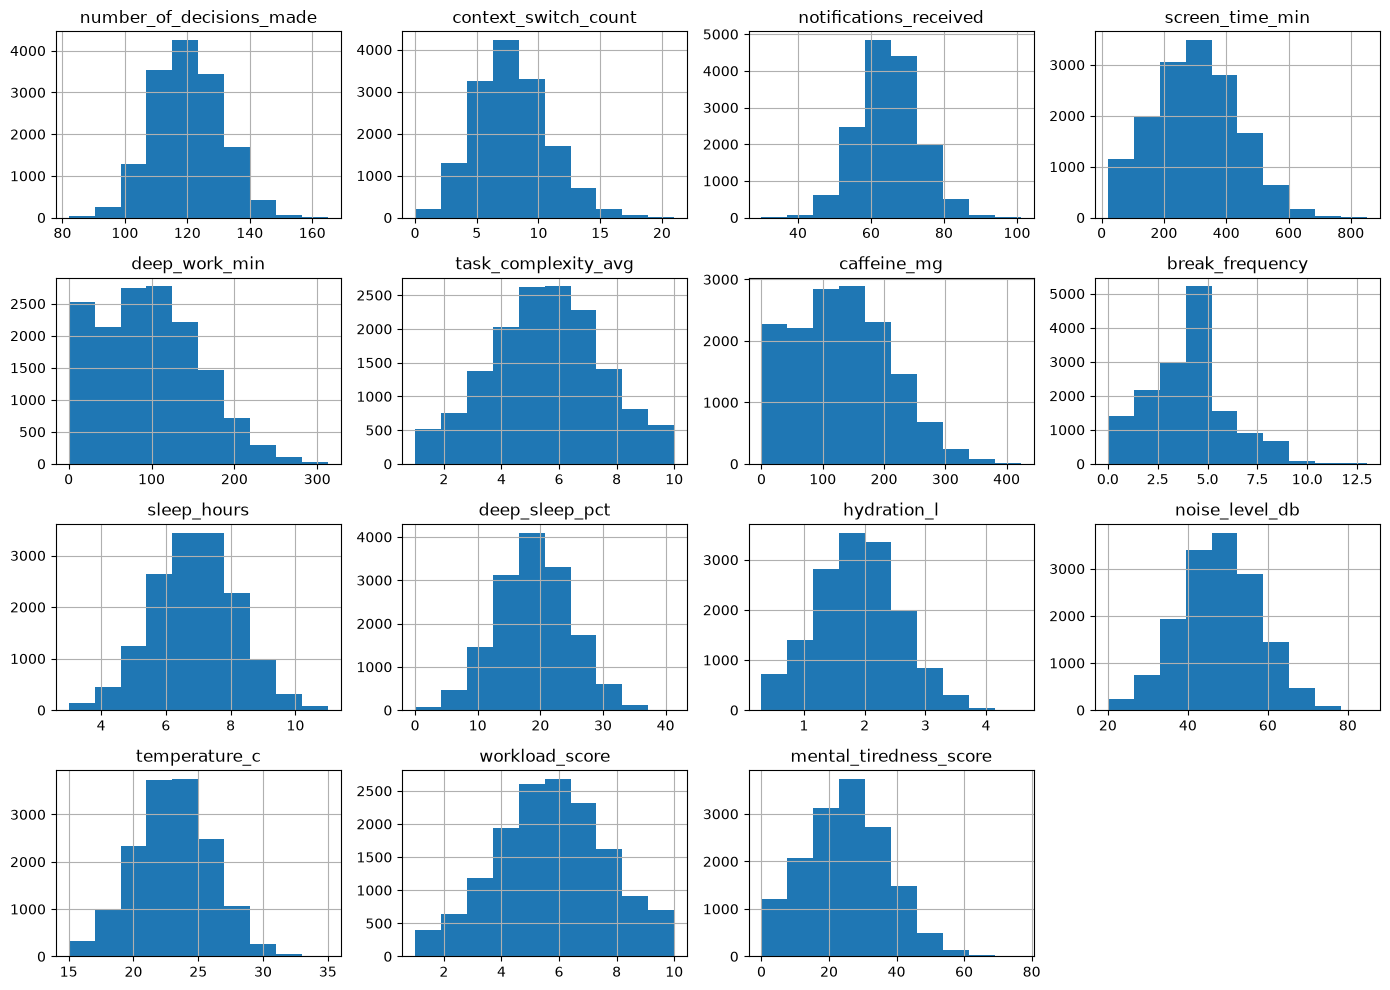

In [24]:
df.hist(figsize=(14, 10))
plt.tight_layout()
plt.show()

## Skewness Check

In [25]:
df.skew(numeric_only=True)

number_of_decisions_made    0.063937
context_switch_count        0.369507
notifications_received      0.104212
screen_time_min             0.119071
deep_work_min               0.298261
task_complexity_avg        -0.016845
caffeine_mg                 0.266219
break_frequency             0.495119
sleep_hours                -0.014786
deep_sleep_pct              0.026630
hydration_l                 0.061899
noise_level_db             -0.004253
temperature_c               0.012999
workload_score             -0.033925
mental_tiredness_score      0.107726
dtype: float64

## Bivariate Analysis

## Sleep vs Mental Tiredness

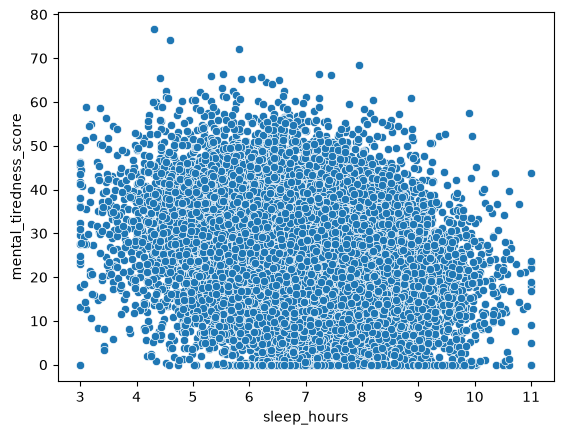

In [26]:
sns.scatterplot(
    x='sleep_hours',
    y='mental_tiredness_score',
    data=df
)
plt.show()

## Screen Time vs Mental Tiredness

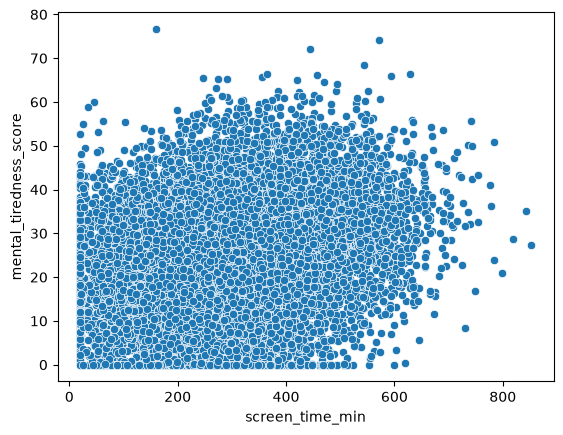

In [27]:
sns.scatterplot(
    x='screen_time_min',
    y='mental_tiredness_score',
    data=df
)
plt.show()

## Workload vs Mental Tiredness

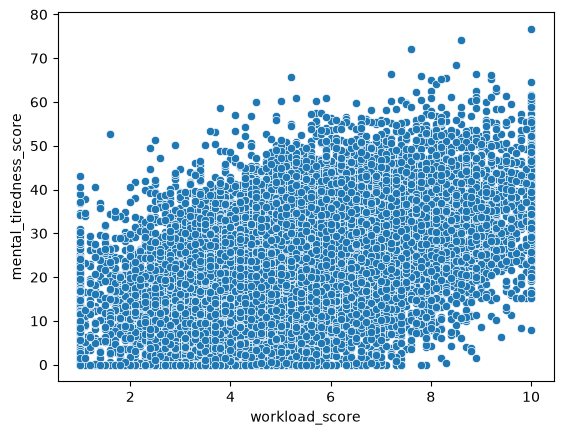

In [28]:
sns.scatterplot(
    x='workload_score',
    y='mental_tiredness_score',
    data =df
)
plt.show()

## Correlation Heatmap

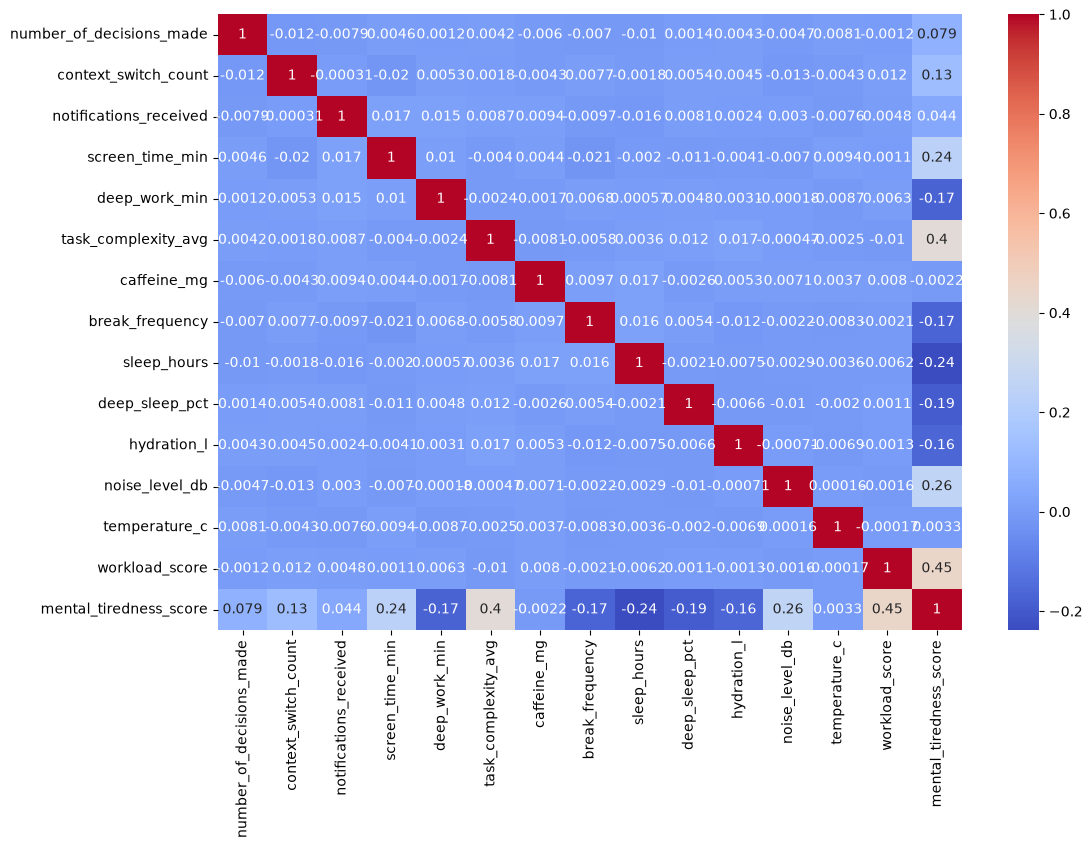

In [29]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot = True,
    cmap='coolwarm'
)

plt.show()

In [30]:
## Mood vs Mental Tiredness

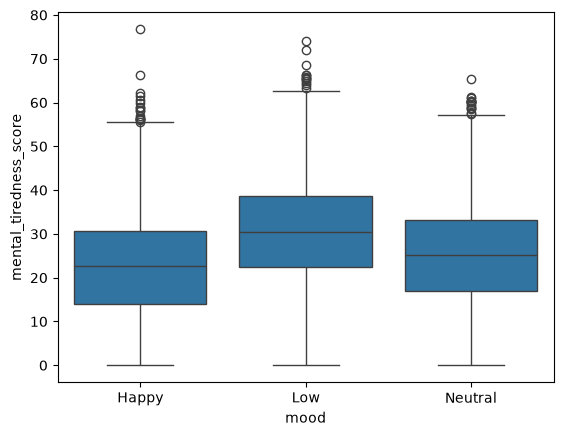

In [31]:
sns.boxplot(
    x='mood',
    y='mental_tiredness_score',
    data=df
)

plt.show()

## Step 5 : Outlier Detection & Treatment

In [32]:
## Boxplot

In [33]:
cat_cols = X.select_dtypes(include='object').columns
num_cols = X.select_dtypes(exclude='object').columns

C:\Users\User\AppData\Local\Temp\ipykernel_6888\142198770.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include='object').columns


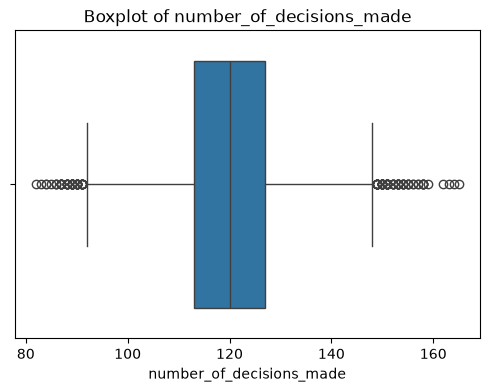

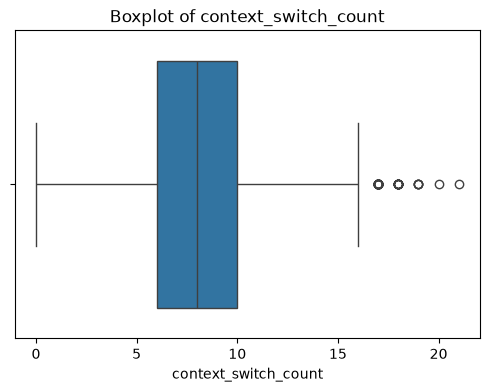

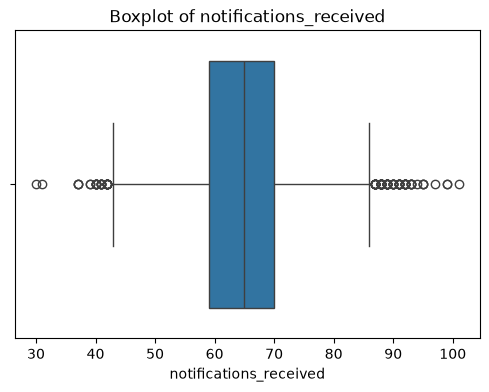

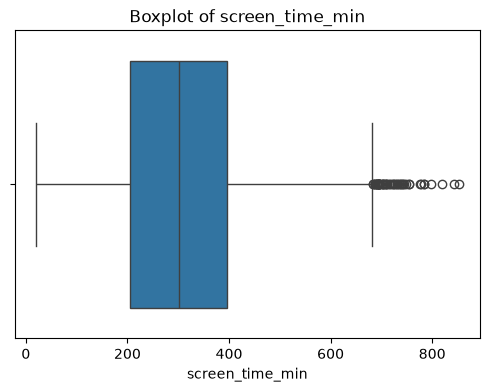

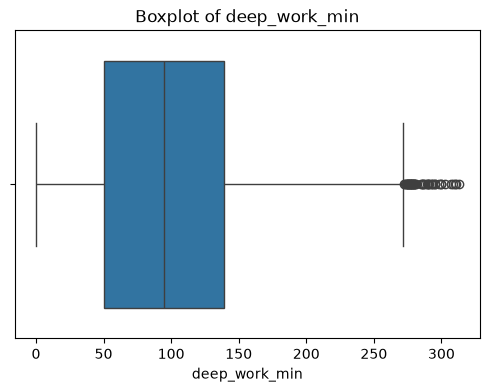

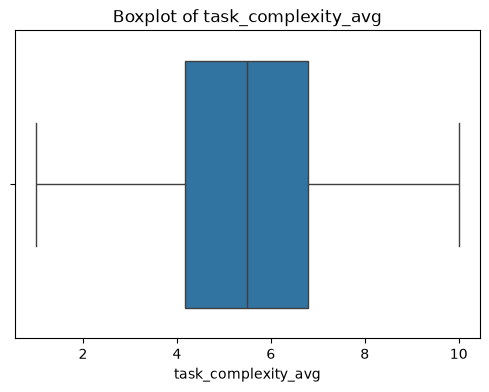

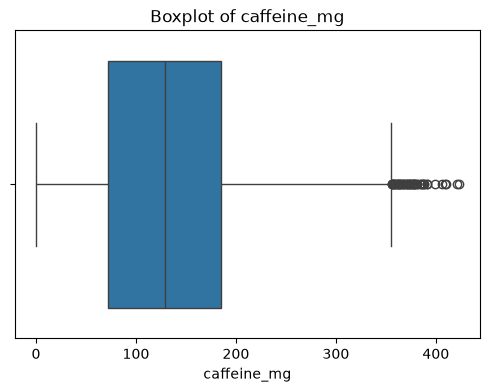

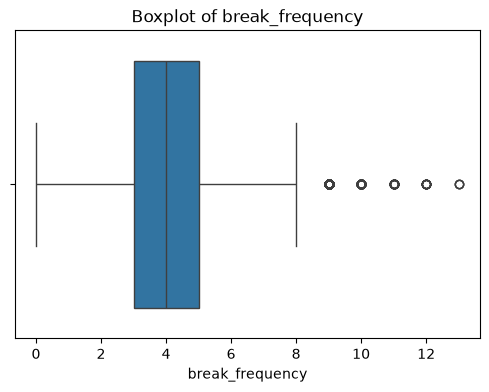

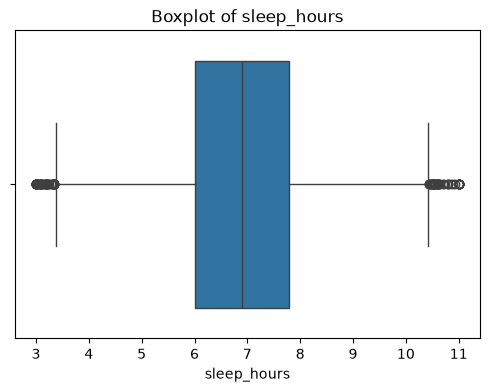

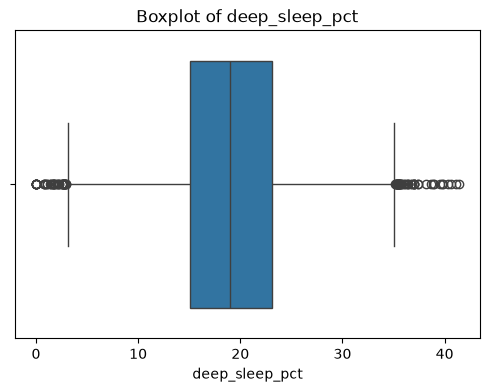

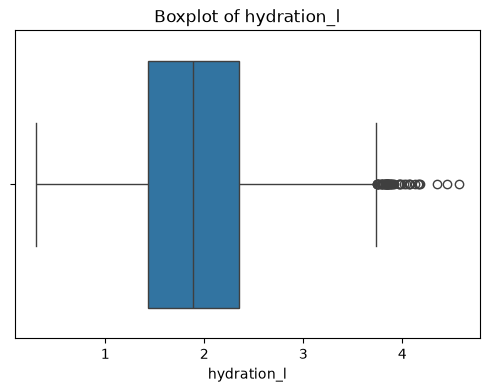

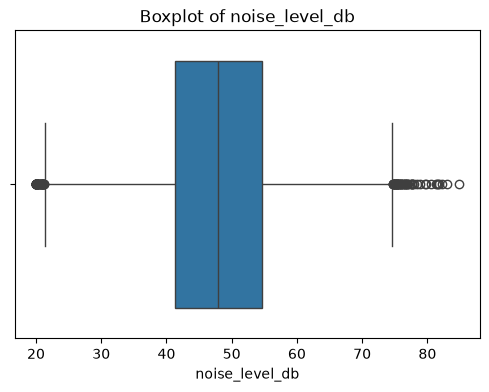

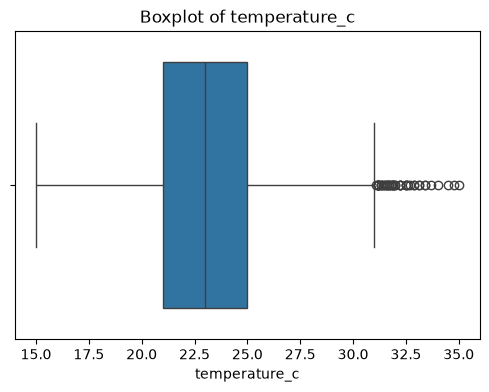

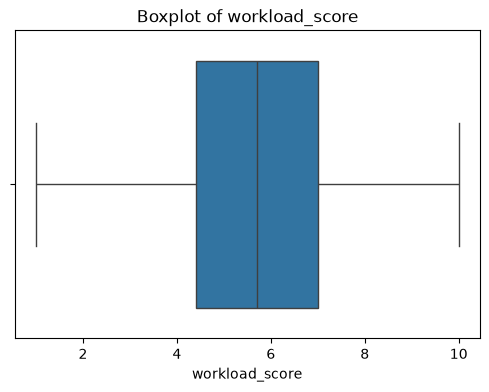

In [34]:
## uses : Boxplots, IQR/Z-Score
#Boxplot

for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

# IQR Method

In [35]:
# Remove outliers using IQR method

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # keep only rows within bounds
    df = df[(df[col]>=lower_bound) & (df[col] <= upper_bound)]

print('Outliers removed successfully')
print('New shape:', df.shape)

Outliers removed successfully
New shape: (13760, 18)


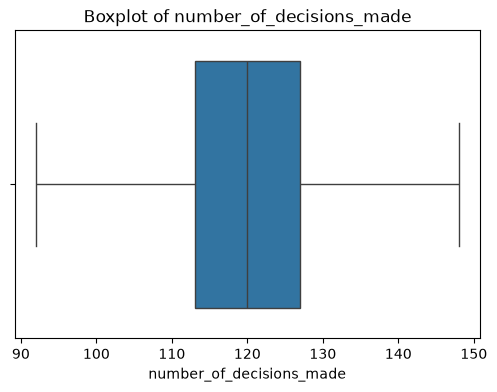

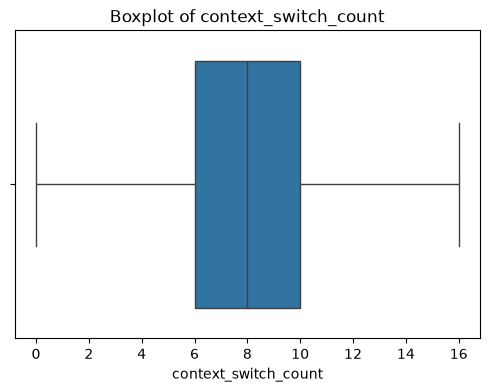

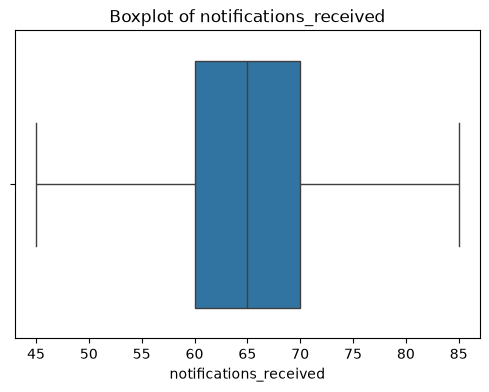

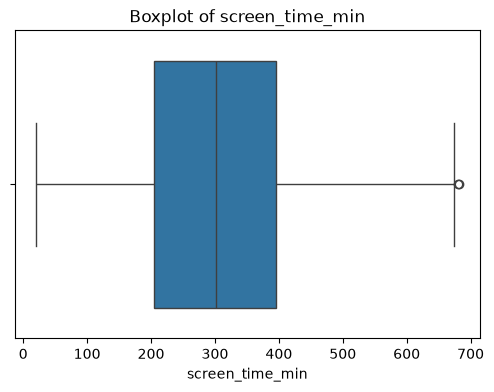

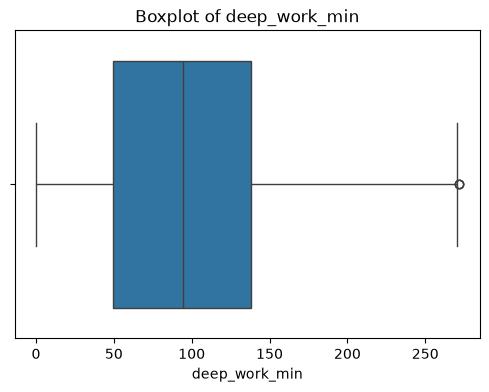

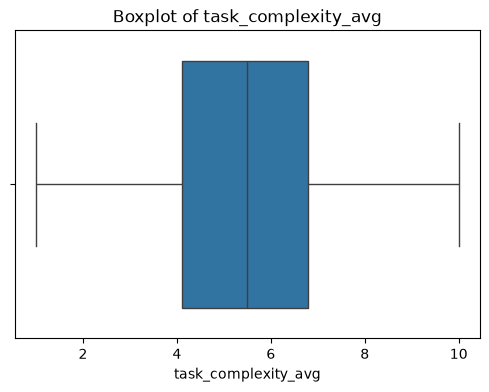

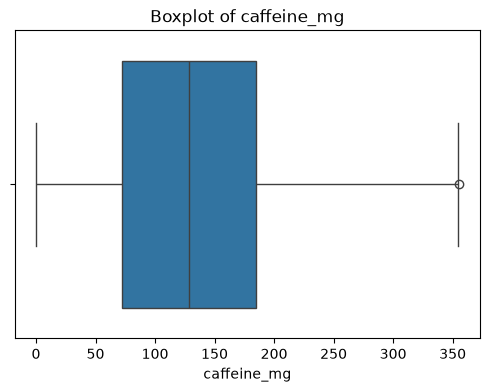

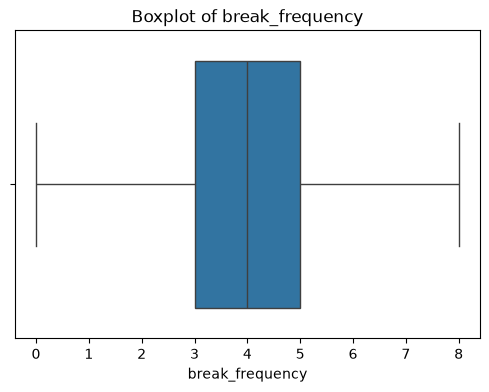

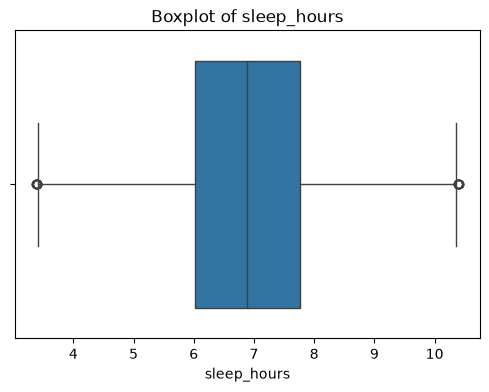

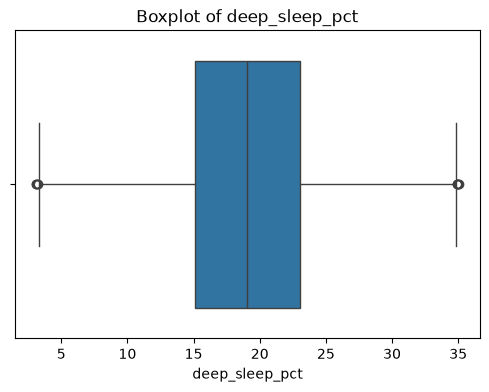

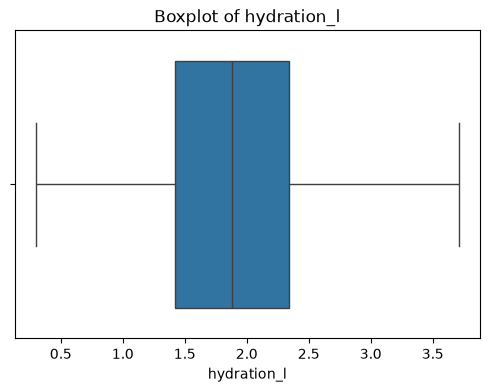

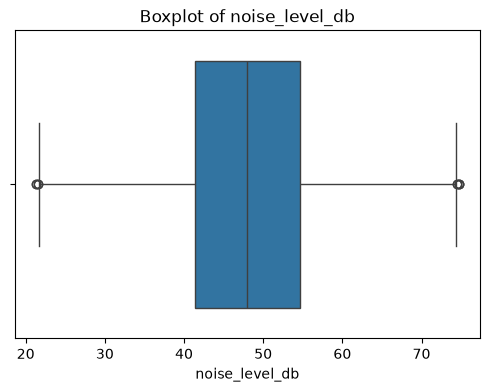

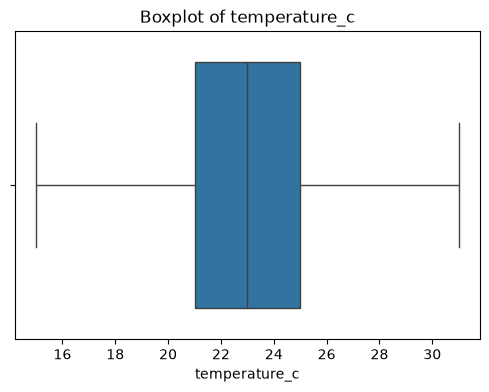

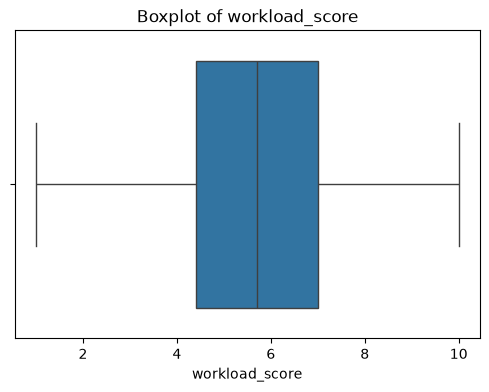

In [36]:
# Here it removes outliers

for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [37]:
X = df.drop(['mental_tiredness_score'], axis=1)

y = df['mental_tiredness_score']

In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size=0.2,
    random_state=42
)

In [39]:
num_cols = X_train.select_dtypes(include=np.number).columns
cat_cols = X_train.select_dtypes(include='object').columns

C:\Users\User\AppData\Local\Temp\ipykernel_6888\3508446868.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include='object').columns


In [40]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [41]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [42]:
df.columns

Index(['number_of_decisions_made', 'context_switch_count',
       'notifications_received', 'screen_time_min', 'deep_work_min',
       'task_complexity_avg', 'caffeine_mg', 'break_frequency', 'sleep_hours',
       'deep_sleep_pct', 'hydration_l', 'mood', 'work_type',
       'work_environment', 'noise_level_db', 'temperature_c', 'workload_score',
       'mental_tiredness_score'],
      dtype='str')

In [43]:
numerical_cols = [
    'number_of_decisions_made',
    'context_switch_count',
    'notifications_received',
    'screen_time_min',
    'deep_work_min',
    'task_complexity_avg',
    'caffeine_mg',
    'break_frequency',
    'sleep_hours',
    'deep_sleep_pct',
    'hydration_l', 
    'noise_level_db', 
    'temperature_c', 
    'workload_score',
]
    

In [44]:
categorical_cols = [
    'mood',
    'work_type',
    'work_environment'
]

In [45]:
df['mood'].value_counts()

mood
Happy      5770
Neutral    5227
Low        2763
Name: count, dtype: int64

In [46]:
df['work_type'].value_counts() # nominal

work_type
Student    4789
Office     4195
Remote     3381
Manual     1395
Name: count, dtype: int64

In [47]:
df['work_environment'].value_counts() # nominal

work_environment
Quiet             5530
Moderate Noise    5473
Noisy             2757
Name: count, dtype: int64

In [48]:
nominal_cols = [
    'work_type',
    'work_environment'
]

In [49]:
# ordinal

In [50]:
mood_order = {
    'Low': 0,
    'Neutral':1,
    'Happy':2
} # ordinal

In [51]:
# ordinal features

In [52]:
mood_order = ['Low', 'Neutral', 'Happy']
env_order = ['Quiet', 'Moderate Noise', 'Noisy']


In [53]:
nominal_cols = ['mood', 'work_environment']

In [54]:
# ordinal pipeline

In [63]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

mood_order = ['Low', 'Neutral', 'Happy']
work_env_order = ['Quiet', 'Moderate Noise', 'Noisy']

ordinal_cols = ['mood', 'work_environment']

In [64]:
ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=[mood_order, work_env_order]))
])

# nominal pipeline

In [65]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [66]:
nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy = 'most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
     ])

In [67]:
from sklearn.preprocessing import OneHotEncoder

OneHotEncoder(handle_unknown='ignore')

,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",True
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequen

In [68]:
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))

])

In [69]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('ord', ordinal_pipeline, ordinal_cols),
    ('nom', nominal_pipeline, nominal_cols)
])

In [70]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)


In [71]:
print('X_train:', X_train_processed.shape)
print('X_test:', X_test_processed.shape)

print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (11008, 22)
X_test: (2752, 22)
y_train: (11008,)
y_test: (2752,)


## Sprint 2

In [73]:
# baseline

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

lr = LinearRegression()
lr.fit(X_train_processed, y_train)

y_pred_lr = lr.predict(X_test_processed)

r2_lr = r2_score(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print('Linear Regression R2 (Accuracy):', r2_lr)

Linear Regression R2 (Accuracy): 0.7518710975096545


## training multiple models

In [159]:
# Linear regression
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train_processed, y_train)

y_pred_lr = lr.predict(X_test_processed)

r2_lr = r2_score(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr)

print('Linear Regression R2 (Accuracy):', r2_lr)


SyntaxError: '(' was never closed (3458437082.py, line 11)

In [82]:
# decision tree regressor

from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train_processed, y_train)

y_pred_dt = dt.predict(X_test_processed)

r2_dt = r2_score(y_test, y_pred_dt)
mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))

print('Decision Tree R2 (Accuracy):', r2_dt)

Decision Tree R2 (Accuracy): 0.21768281564081604


In [85]:
# random forest regressor
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train_processed, y_train)

y_pred_rf = rf.predict(X_test_processed)

r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print('Random Forest R2 (Accuracy):', r2_rf)

Random Forest R2 (Accuracy): 0.6525434054147425


In [86]:
# gradient boosting regressor

from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train_processed, y_train)

y_pred_gb = gb.predict(X_test_processed)

r2_gb = r2_score(y_test, y_pred_gb)
mae_gb=mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))

print('Gradient Boosting R2 (Accuracy):', r2_gb)

Gradient Boosting R2 (Accuracy): 0.7011926346485142


In [ ]:
# Step 3: Model Evaluation
# Regression Metric
# MAE
# RMSE
# R2

In [88]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

In [89]:
# Linear Regression

mae_lr, rmse_lr, r2_lr = evaluate_model(y_test, y_pred_lr)
mae_lr, rmse_lr, r2_lr


(4.776957179862363, np.float64(5.9628052512577865), 0.7518710975096545)

In [90]:
# Decision Tree

mae_dt, rmse_dt, r2_dt = evaluate_model(y_test, y_pred_dt)
mae_dt, rmse_dt, r2_dt

(8.385381540697674, np.float64(10.587742805279877), 0.21768281564081604)

In [91]:
# Random Forest

mae_rf, rmse_rf, r2_rf = evaluate_model(y_test, y_pred_rf)
mae_rf, rmse_rf, r2_rf

(5.661164207848837, np.float64(7.056059387265974), 0.6525434054147425)

In [92]:
## Gradient Boosting
mae_gb, rmse_gb, r2_gb = evaluate_model(y_test, y_pred_gb)
mae_gb, rmse_gb, r2_gb

(5.238277589717889, np.float64(6.5434621872750425), 0.7011926346485142)

# Step 4 : Overfitting & Underfitting Check
# Compare: Training vs Testing performance

In [93]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [94]:
models = {
    'Linear Regression': lr,
    'Decision Tree':dt,
    'Random Forest':rf,
    'Gradient Boosting':gb
}
    

In [95]:
for name, model in models.items():

    train_pred = model.predict(X_train_processed)
    test_pred = model.predict(X_test_processed)

    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    train_mae = mean_absolute_error(y_train, train_pred)
    test_mae = mean_absolute_error(y_test, test_pred)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    print(f'\n{name}')
    print('Train R2 Score:', round(train_r2, 4))
    print('Test R2 Score :', round(test_r2, 4))
    print('Train MAE :', round(train_mae, 4))
    print('Test MAE :', round(test_mae, 4))
    print('Trian RMSE :', round(train_rmse, 4))
    print('Test RMSE :', round(test_rmse, 4))

    


Linear Regression
Train R2 Score: 0.7485
Test R2 Score : 0.7519
Train MAE : 4.8537
Test MAE : 4.777
Trian RMSE : 6.0955
Test RMSE : 5.9628

Decision Tree
Train R2 Score: 1.0
Test R2 Score : 0.2177
Train MAE : 0.0
Test MAE : 8.3854
Trian RMSE : 0.0
Test RMSE : 10.5877

Random Forest
Train R2 Score: 0.9521
Test R2 Score : 0.6525
Train MAE : 2.115
Test MAE : 5.6612
Trian RMSE : 2.6601
Test RMSE : 7.0561

Gradient Boosting
Train R2 Score: 0.7442
Test R2 Score : 0.7012
Train MAE : 4.9284
Test MAE : 5.2383
Trian RMSE : 6.1474
Test RMSE : 6.5435


# 4 . Model Comparsion Table

In [102]:
import pandas as pd

results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],

    'MAE':[mae_lr, mae_dt, mae_rf, mae_gb],
    'RMSE':[rmse_lr, rmse_dt, rmse_rf, rmse_gb],
    'R2 Score': [r2_lr , r2_dt, r2_rf, r2_gb]
})

results.sort_values(by='R2 Score', ascending=False)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.776957,5.962805,0.751871
3,Gradient Boosting,5.238278,6.543462,0.701193
2,Random Forest,5.661164,7.056059,0.652543
1,Decision Tree,8.385382,10.587743,0.217683


## Sprint 3

# STEP 1 :: FEATURE ENGINEERING
# Create meaningful new features
# 1. Work Stress Ration

In [104]:
df['stress_per_workload'] = df['screen_time_min']/(df['workload_score']+1)

df['sleep_quality'] = df['deep_sleep_pct'] * df['sleep_hours']

df['productivity_index'] = df['deep_work_min'] / (df['screen_time_min']+1)

In [105]:
# STEP 2: FEATURE SELECTION

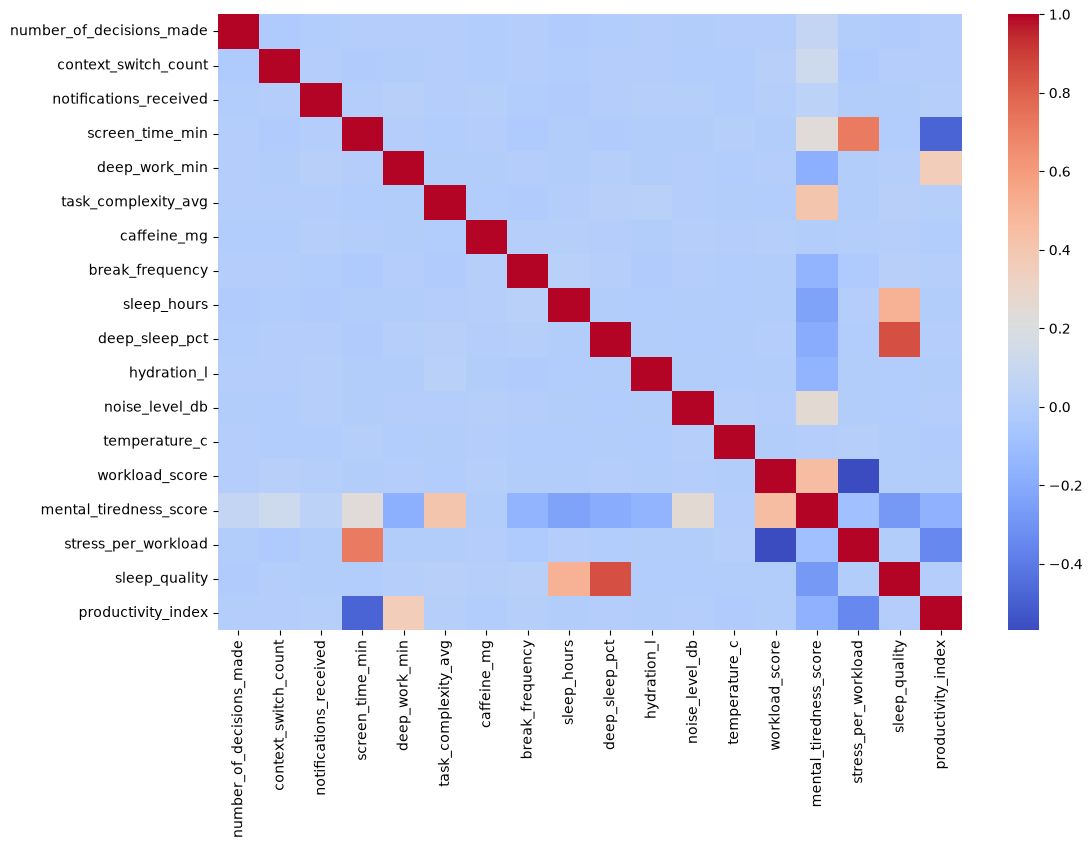

In [109]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_df = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), cmap='coolwarm')
plt.show()

In [111]:
# 3. Feature Importance (Random Forest)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor()
rf.fit(X_train_processed, y_train)

importances = rf.feature_importances_


In [ ]:
## STEP 3: HYPERPARAMETER TUNING

In [115]:
## linear regression

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression

lr_params = {
    'fit_intercept': [True, False]
}

lr_grid = GridSearchCV(
    LinearRegression(),
    param_grid = lr_params,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

lr_grid.fit(X_train_processed, y_train)

print('Best Parameters:', lr_grid.best_params_)
print('Best CV Score:', lr_grid.best_score_)

Best Parameters: {'fit_intercept': True}
Best CV Score: 0.7472250471915305


In [116]:
! pip install scikit-optimize

Defaulting to user installation because normal site-packages is not writeable


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [126]:
# Gradient
from skopt import BayesSearchCV
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(random_state=42)

search_space = {
    'n_estimators': (50, 300),
    'learning_rate':(0.01, 0.2, 'log-uniform'),
    'max_depth':(3,10),
    'subsample':(0.6, 1.0),
}
    

In [128]:
bayes_search=BayesSearchCV(
    gb,
    search_spaces=search_space,
    n_iter=20,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    random_state=42
)

bayes_search.fit(X_train_processed, y_train)
best_model = bayes_search.best_estimator_

print(bayes_search.best_params_)

OrderedDict({'learning_rate': 0.10488697056375174, 'max_depth': 3, 'n_estimators': 210, 'subsample': 0.8639364472767374})


In [130]:
# random forest

from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

rf_params = {
    'n_estimators':[100,200],
    'max_depth':[5, 10, None],
    'min_samples_split':[2,5],
    'min_samples_leaf':[1,2],
    'max_features':['sqrt','log2']
}

In [132]:
rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid=rf_params,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    error_score='raise'
)

rf_grid.fit(X_train_processed, y_train)

print(rf_grid.best_params_)
best_rf_model=rf_grid.best_estimator_


{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [ ]:
## Decision tree

In [137]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

dt_params = {
    'max_depth':[3,5,7,10, None],
    'min_samples_split':[2,5,10],
    'min_samples_leaf':[1,2,4],
    'criterion':['squared_error']
}

In [138]:
dt_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid=dt_params,
    cv=3,
    scoring='r2',
    n_jobs=-1
)

dt_grid.fit(X_train_processed, y_train)
print(dt_grid.best_params_)
best_dt_model = dt_grid.best_estimator_

{'criterion': 'squared_error', 'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 10}


In [ ]:
## Evaluate all tuned models

In [139]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

In [141]:
models = {
    'Linear Regression': best_lr_model,
    'Decision Tree': best_dt_model,
    'Random Forest': best_rf_model,
    'Gradient Boosting': best_model
}

NameError: name 'best_lr_model' is not defined

In [144]:
for name, model in models.items():
    train_pred = model.predict(X_train_processed)
    test_pred = model.predict(X_test_processed)

    print('='*50)
    print(name)

    # R2 Score
    print('Train R2 Score:', r2_score(y_train, train_pred))
    print('Test R2 Score:', r2_score(y_test, test_pred))


    # MAE
    print('Train MAE:', mean_absolute_error(y_train, train_pred))
    print('Test MAE:', mean_absolute_error(y_test, test_pred))


    # RMSE
    print('Train RMSE:', np.sqrt(mean_squared_error(y_train, train_pred)))
    print('Test RMSE:', np.sqrt(mean_squared_error(y_test, test_pred)))
    

Linear Regression
Train R2 Score: 0.7484966240090836
Test R2 Score: 0.7518710975096545
Train MAE: 4.853692826688232
Test MAE: 4.776957179862363
Train RMSE: 6.095461709066712
Test RMSE: 5.9628052512577865
Decision Tree
Train R2 Score: 1.0
Test R2 Score: 0.21768281564081604
Train MAE: 0.0
Test MAE: 8.385381540697674
Train RMSE: 0.0
Test RMSE: 10.587742805279877
Random Forest
Train R2 Score: 0.9521015649127788
Test R2 Score: 0.6525434054147425
Train MAE: 2.1149527616279076
Test MAE: 5.661164207848837
Train RMSE: 2.660084056455919
Test RMSE: 7.056059387265974
Gradient Boosting
Train R2 Score: 0.7441888044701754
Test R2 Score: 0.7011926346485142
Train MAE: 4.928390984694024
Test MAE: 5.238277589717889
Train RMSE: 6.147442447875177
Test RMSE: 6.5434621872750425


In [145]:
## STEP 4 : BUILD FINAL MODEL
from sklearn.linear_model import LinearRegression

final_model = LinearRegression()

final_model.fit(X_train_processed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](22,)","[ 0.91, 1.58, 0.34,..., 0.16,-0.41, 0.25]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,29.48
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,22
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(18)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](22,)","[108.07,107.63,106.7 ,..., 0. , 0. , 0. ]"


## STEP 5 : FINAL EVALUATION

In [146]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

y_pred = final_model.predict(X_test_processed)

print('FINAL MODEL PERFORMANCE')
print('R2 Score :', r2_score(y_test, y_pred))
print('MAE : ', mean_absolute_error(y_test, y_pred))
print('RMSE :', np.sqrt(mean_squared_error(y_test, y_pred)))

FINAL MODEL PERFORMANCE
R2 Score : 0.7518710975096545
MAE :  4.776957179862363
RMSE : 5.9628052512577865


In [ ]:
## step 6 : Model Serialization

In [147]:
full_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', final_model)
])

full_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['number_of_decisions_made','context_switch_count', 'notifications_received',...,'noise_level_db','temperature_c', 'workload_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto 

In [148]:
import joblib

joblib.dump(full_model, 'mental_tiredness_pipeline.pkl')


['mental_tiredness_pipeline.pkl']

In [149]:
model = joblib.load('mental_tiredness_pipeline.pkl')

## SPRINT 4

In [152]:
# Step 1 : Build ML Pipeline

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

In [153]:
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier())
])

In [158]:
import pickle # save the model

In [160]:
with open('Gradient Boosting.pkl','wb') as f:
    pickle.dump(model,f)

In [161]:
with open('Gradient Boosting.pkl', 'wb') as f:
    pickle.dump(model, f)